# Project 2: Image Classification
## Notebook 4 — Interpretability: Saliency & CAM

I compared raw saliency, SmoothGrad and Grad-CAM for the three trained hammer classifiers. I used the saved test split and models from Notebooks 2 and 3.

**Main finding:** EfficientNetV2M had the highest recorded test accuracy (94.54%) and the smallest border-occlusion drop (7.56 percentage points). This does not establish deployment readiness: several displayed images contain text, collages or rendered tools that need another cleaning review.

**Completion status:** The maps and ablation results are present. The final output still lists 18 unfinished visual-review rows and six blank deployment fields, so final review exports are not confirmed.

### 0. Setup
**Task:** I loaded the shared configuration and image folders.  
**Decision:** I kept the same paths and random seed as the earlier notebooks.  
**Steps taken:** I imported the helper functions, set the seed and printed the working directories.

In [6]:
from pathlib import Path
import sys, json, time, hashlib, random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

# Locate the repository from its root or notebooks folder.
REPO_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == 'notebooks'
    else Path.cwd()
)

sys.path.insert(0, str(REPO_ROOT / 'notebooks'))
sys.path.insert(0, str(REPO_ROOT / 'app'))

from pipeline_utils import (
    ROOT, load_config, save_json, digest, checked_manifest,
    as_bool, resize_rgb, pixel_hash, dhash, prepared_inputs
)

# Load the same configuration used by the earlier notebooks.
config, DATA_ROOT = load_config()

# Match Notebook 1's scraped-image directory and Notebook 2's exports.
RAW = DATA_ROOT / 'raw'
PREPARED = DATA_ROOT / 'prepared'

# Set reproducible random seeds.
SEED = config['seed']
np.random.seed(SEED)
random.seed(SEED)

pd.set_option('display.max_rows', 25)
plt.style.use('default')

# Use the project title instead of the removed team setting.
print(config.get('project_title', 'Project 2: Image Classification'))
print('Notebook 4: Explainability and Interpretation')
print('External data directory:', DATA_ROOT)
print('Scraped image directory:', RAW)
print('Prepared data directory:', PREPARED)

Project 2: Image Classification
Notebook 4: Explainability and Interpretation
External data directory: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images
Scraped image directory: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw
Prepared data directory: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\prepared


**Output and interpretation:** I confirmed that the notebook points to `Images/raw` and `Images/prepared`. These paths keep the explanation inputs aligned with the earlier pipeline.


### 1.1 Load And Verify the Trained Models
**Task:** I rebuilt each model and checked its test predictions.  
**Decision:** I reused the saved split, class mapping and trained probes to keep this analysis consistent with Notebook 3.  
**Steps taken:** I checked file hashes, joined each frozen backbone to its probe, compared saved predictions and measured the CAM grid.

I passed raw 0–255 images to the explanation helper and applied model-specific preprocessing only for direct predictions. This avoids scaling an image twice.

In [8]:
import keras
import tensorflow as tf
import image_explainers as xai

from project_utils import join_model
from sklearn.metrics import accuracy_score

# Load the verified preprocessing exports from Notebook 2.
PREPARED, preprocessing, mapping, class_names, arrays = prepared_inputs(
    config, DATA_ROOT
)
_, X_test, _, y_test = arrays

MODELS = ROOT / 'models'
training = json.loads(
    (MODELS / 'training_metadata.json').read_text(encoding='utf-8')
)

# Verify that Notebook 3 used the current configuration and prepared data.
assert training['config_sha256'] == digest(
    ROOT / 'config/project.json'
), 'Configuration changed since Notebook 3.'

assert training['preprocessing_sha256'] == digest(
    PREPARED / 'preprocessing.json'
), 'Preprocessing exports changed since Notebook 3.'

assert json.loads(
    (MODELS / 'label_to_index.json').read_text(encoding='utf-8')
) == mapping, 'Notebook 3 label mapping differs from Notebook 2.'

joined_models = {}
predictions = {}
baselines = {}
grids = {}

for name in config['applications']:
    # Verify the saved model against Notebook 3's recorded hash.
    probe_path = MODELS / f'P2_N3_{name}.keras'

    if not probe_path.is_file():
        raise FileNotFoundError(f'Missing trained model: {probe_path}')

    expected_hash = training['probe_sha256'].get(name)
    actual_hash = digest(probe_path)

    if expected_hash != actual_hash:
        raise ValueError(
            f"\nModel integrity mismatch: {name}"
            f"\nFile: {probe_path}"
            f"\nHash recorded by Notebook 3: {expected_hash}"
            f"\nHash of the current file:   {actual_hash}"
            "\n\nRestore the matching model and metadata from the same "
            "Notebook 3 run, or rerun Notebook 3 top-to-bottom to "
            "regenerate models, predictions, and metadata together."
        )

    # Reconstruct the frozen backbone and trained classifier.
    model, base = join_model(
        name, MODELS, tuple(config['target_size'])
    )
    joined_models[name] = model
    preprocess = xai.find_preprocess_input(base)

    # Predict using the same application-specific preprocessing.
    batches = []

    for start in range(0, len(X_test), config['batch_size']):
        batch = np.array(
            X_test[start:start + config['batch_size']],
            dtype='float32',
            copy=True
        )
        batches.append(
            model(preprocess(batch), training=False).numpy()
        )

    probabilities = np.concatenate(batches, axis=0)
    predictions[name] = probabilities.argmax(axis=1)
    baselines[name] = accuracy_score(y_test, predictions[name])

    # Confirm agreement with the explainer's raw-image prediction route.
    np.testing.assert_allclose(
        xai.predict_proba(model, X_test[0]),
        probabilities[0],
        atol=1e-5
    )

    # Confirm agreement with Notebook 3's saved class predictions.
    saved = pd.read_csv(
        PREPARED / f'{name}_test_predictions.csv'
    )
    assert np.array_equal(
        predictions[name],
        saved['predicted'].to_numpy()
    ), f'{name}: predictions differ from Notebook 3.'

    # Find the final spatial feature layer used for CAM.
    map_layers = [
        layer for layer in base.layers
        if not isinstance(layer, keras.layers.InputLayer)
        and len(layer.output.shape) == 4
    ]

    if not map_layers:
        raise ValueError(f'{name}: no spatial feature layer found for CAM.')

    grids[name] = tuple(
        int(value) for value in map_layers[-1].output.shape[1:3]
    )

    print(
        name,
        '| CAM grid:', grids[name],
        '| baseline accuracy:', f'{baselines[name]:.4f}'
    )

mobilenetv2 | CAM grid: (7, 7) | baseline accuracy: 0.9034
resnet50 | CAM grid: (7, 7) | baseline accuracy: 0.9370
efficientnetv2m | CAM grid: (7, 7) | baseline accuracy: 0.9454


#### Output and interpretation
| Model | Test accuracy | Errors reported below | CAM grid |
|---|---:|---:|---|
| MobileNetV2 | 90.34% | 23 | 7 × 7 |
| ResNet50 | 93.70% | 15 | 7 × 7 |
| EfficientNetV2M | 94.54% | 13 | 7 × 7 |

I found that EfficientNetV2M scored 4.20 percentage points above MobileNetV2. Every CAM starts from a coarse 7 × 7 grid; enlarging it does not provide precise object boundaries. Accuracy alone does not show whether a model uses the right visual cues.

### 2.1 Explaining the Correct Predictions and Mistakes
**Task:** I examined three correct cases and three errors per model.  
**Decision:** I selected one correct image per class and the first three actual errors, rather than choosing only convincing maps.  
**Steps taken:** I generated raw saliency, SmoothGrad with 32 samples and Grad-CAM for each predicted class, then created the review log.

These 18 model–image cases are selected examples, not a representative sample of the full test set. The three methods describe different aspects of model sensitivity and evidence.

## Model: mobilenetv2 — correct examples and real errors

Correct classes covered: 3 | actual errors available: 23


**mobilenetv2 | correct | test index 0**

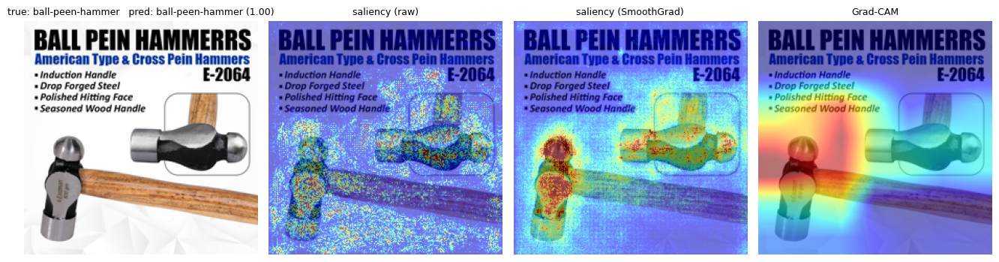

**mobilenetv2 | correct | test index 5**

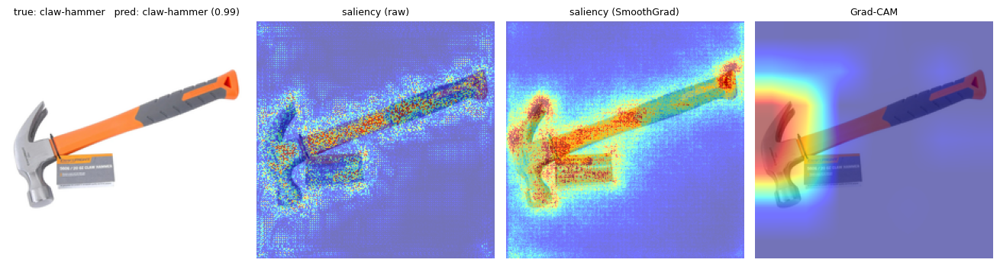

**mobilenetv2 | correct | test index 1**

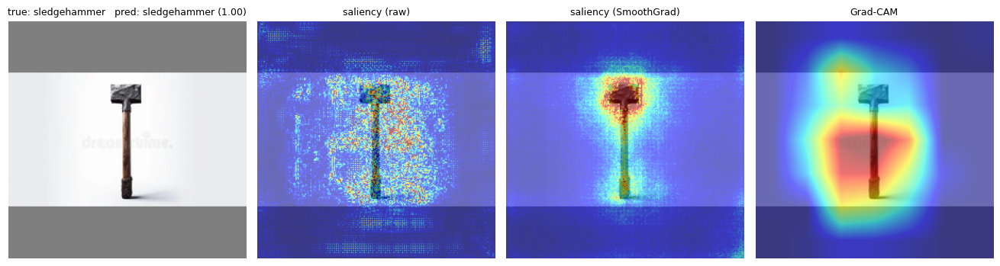

**mobilenetv2 | misclassified | test index 6**

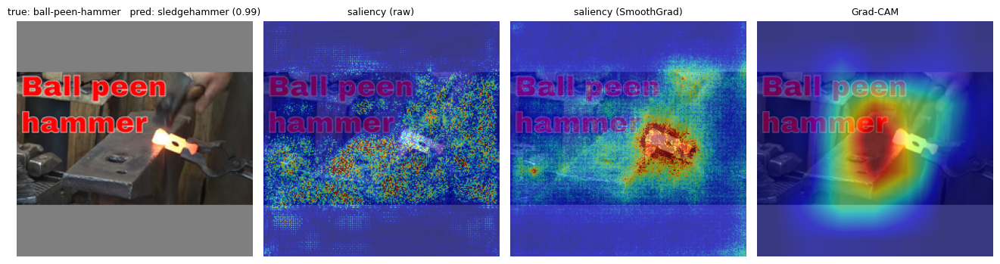

**mobilenetv2 | misclassified | test index 9**

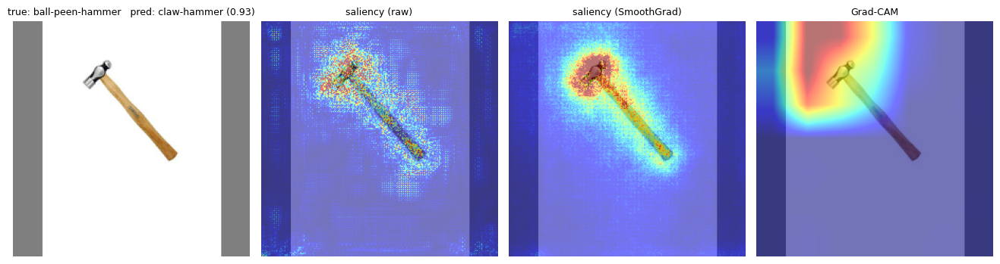

**mobilenetv2 | misclassified | test index 13**

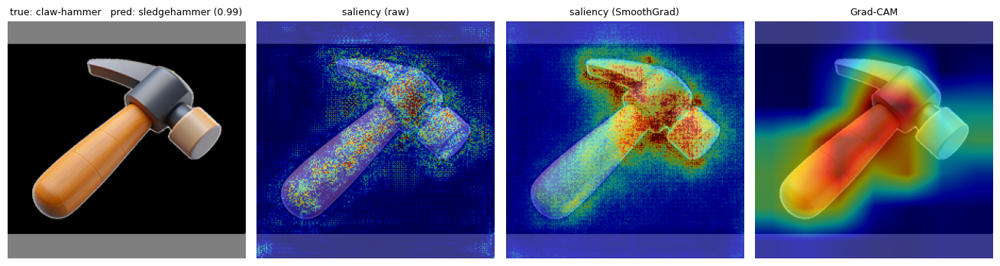

## Model: resnet50 — correct examples and real errors

Correct classes covered: 3 | actual errors available: 15


**resnet50 | correct | test index 0**

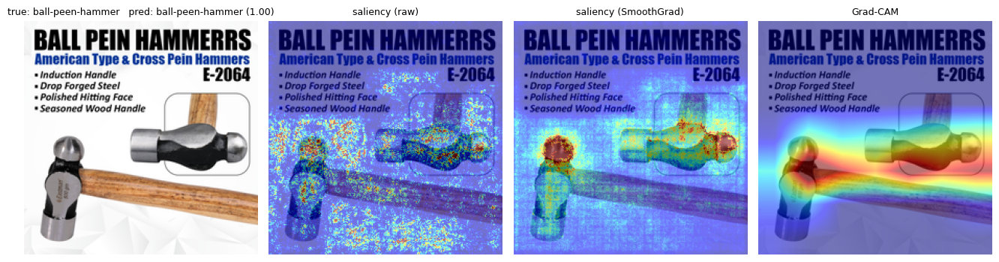

**resnet50 | correct | test index 5**

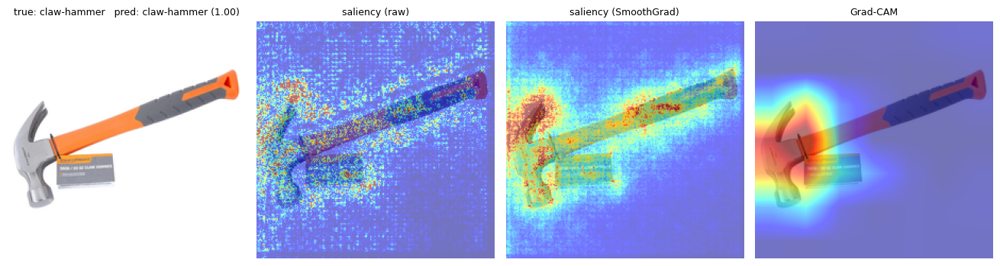

**resnet50 | correct | test index 1**

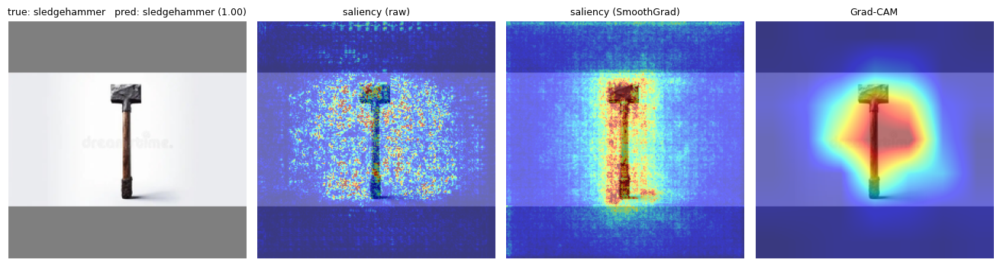

**resnet50 | misclassified | test index 6**

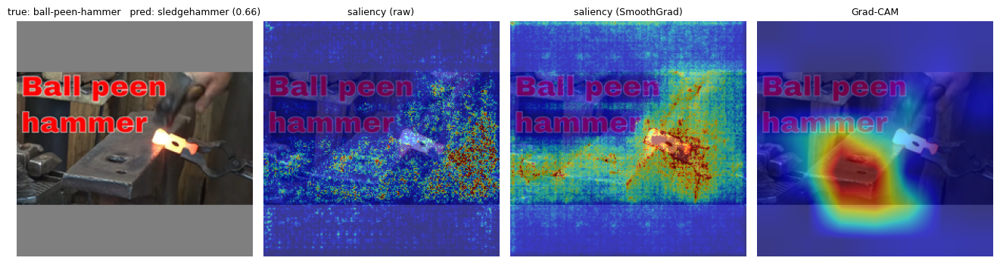

**resnet50 | misclassified | test index 8**

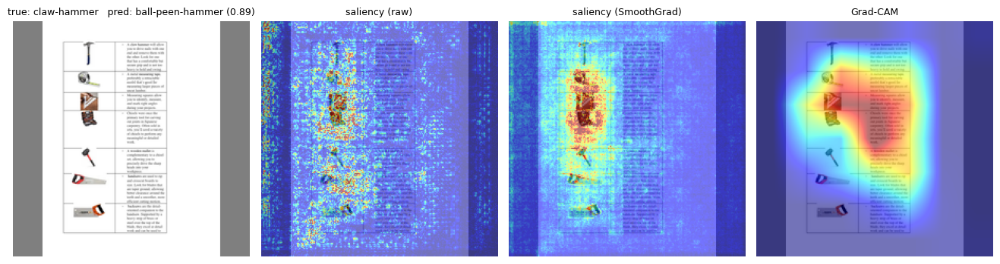

**resnet50 | misclassified | test index 54**

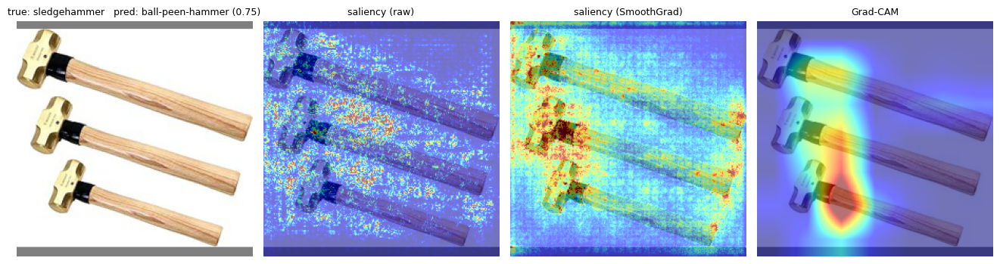

## Model: efficientnetv2m — correct examples and real errors

Correct classes covered: 3 | actual errors available: 13


**efficientnetv2m | correct | test index 0**

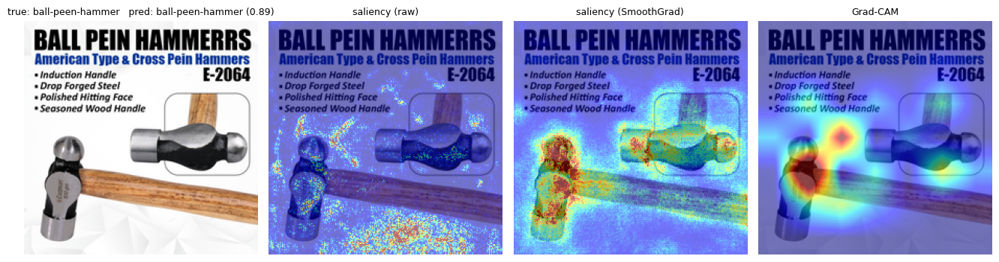

**efficientnetv2m | correct | test index 5**

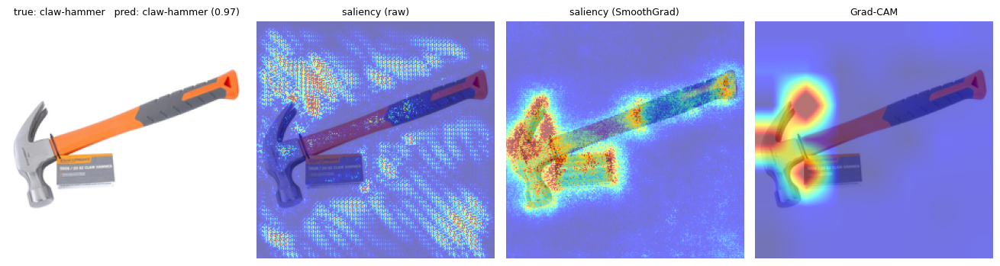

**efficientnetv2m | correct | test index 1**

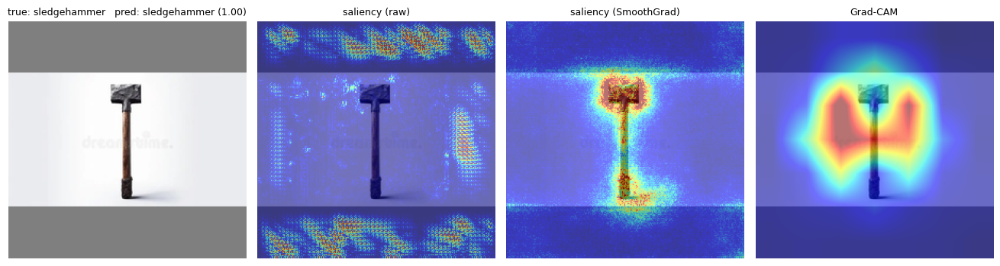

**efficientnetv2m | misclassified | test index 6**

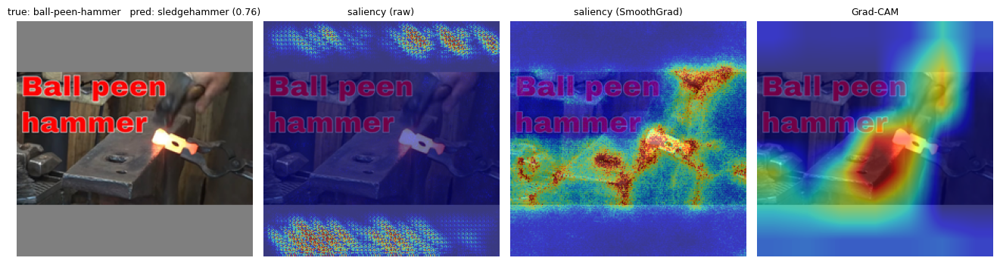

**efficientnetv2m | misclassified | test index 47**

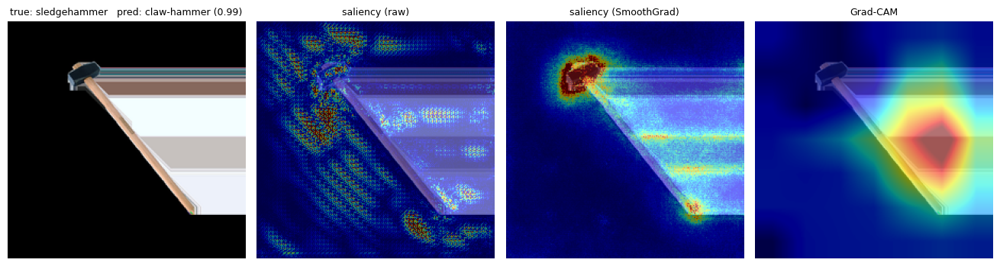

**efficientnetv2m | misclassified | test index 50**

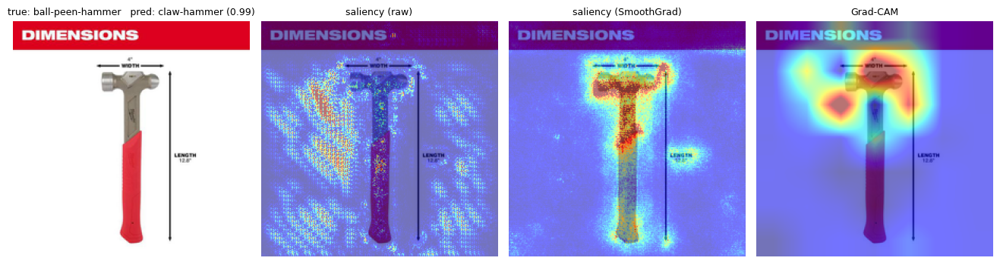

Record actual visual observations in: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\P2_xai_review.csv


In [9]:
observations = []
for name, model in joined_models.items():
    display(Markdown(f'## Model: {name} — correct examples and real errors'))
    prediction = predictions[name]
    correct = []
    for label_index in range(len(class_names)):
        candidates = np.flatnonzero((y_test == label_index) & (prediction == y_test))
        if len(candidates): correct.append(int(candidates[0]))
    correct = correct[:3]
    errors = np.flatnonzero(prediction != y_test)[:3].tolist()
    print('Correct classes covered:', len(correct), '| actual errors available:', int((prediction != y_test).sum()))
    if len(correct) < 3 or len(errors) < 3:
        print('REQUIREMENT SHORTFALL: disclose available real cases; do not invent any.')
    for kind, selected in [('correct',correct), ('misclassified',errors)]:
        for index in selected:
            np.random.seed(SEED + index)
            display(Markdown(f'**{name} | {kind} | test index {index}**'))
            xai.explain(model, X_test[index], class_names, true_label=int(y_test[index]), smooth=32)
            observations.append({'application': name, 'test_index': index, 'case': kind,
                                 'true_class': class_names[int(y_test[index])],
                                 'predicted_class': class_names[int(prediction[index])],
                                 'raw_vs_smoothgrad': '', 'gradcam_region': '',
                                 'shortcut_evidence': '', 'mean_image_link': '',
                                 'methods_agree': '', 'interpretation': ''})
log_path = DATA_ROOT / 'P2_xai_review.csv'
if log_path.exists():
    prior = pd.read_csv(log_path, keep_default_na=False)
    fresh = pd.DataFrame(observations)
    keys = ['application','test_index','case']
    observation_log = fresh[keys + ['true_class','predicted_class']].merge(
        prior.drop(columns=['true_class','predicted_class'],errors='ignore'), on=keys, how='left').fillna('')
else:
    observation_log = pd.DataFrame(observations)
observation_log.to_csv(log_path,index=False)
print('Record actual visual observations in:', log_path)

#### Output and Interpretation
I obtained six case panels per model, with no shortage of real errors. SmoothGrad generally made the tool structure easier to see than raw saliency; Grad-CAM showed broader regions.

- I saw all three models misclassify test image 6, a workshop scene labeled ball-peen hammer. MobileNetV2 displayed 0.99 confidence in its wrong prediction, showing that confidence can be misleading.
- I saw ResNet50's image 8 highlight part of a multi-tool chart and its text area. This suggests a possible context cue, but does not prove a shortcut.
- I found a rendered claw hammer (MobileNetV2 image 13), a product collage (ResNet50 image 54), and dimension annotations (EfficientNetV2M image 50). I would revisit these examples against the cleaning rules before treating the dataset as deployment evidence.

I cannot compare these cases with Notebook 2's mean images because those outputs are not included here.

### 3.1 Compare The same Image Across Models
**Task:** I compared all three models on test image 0.  
**Decision:** I fixed both the image and target class to separate model differences from image differences.  
**Steps taken:** I used the true ball-peen label as the shared target and plotted the original image beside each explanation method.

I compared highlighted locations, not heat intensity across separately normalized maps.

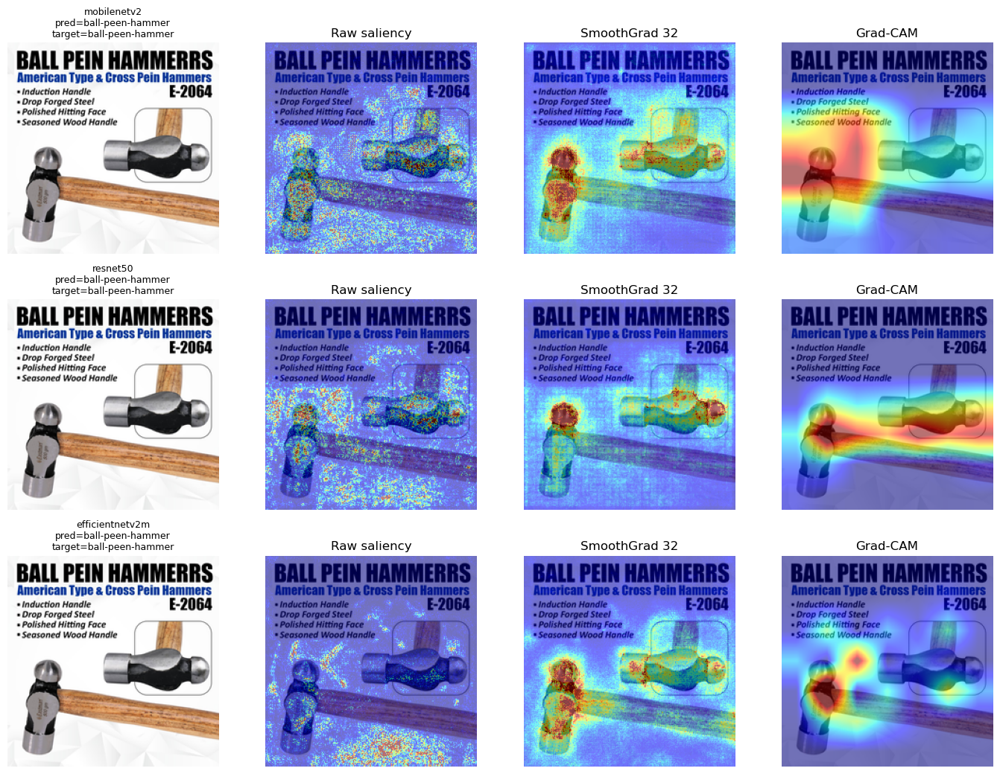

In [10]:
anchor_index = 0
anchor = X_test[anchor_index]
shared_target = int(y_test[anchor_index])
fig, axes = plt.subplots(len(joined_models),4,figsize=(14,3.5*len(joined_models)),squeeze=False)
for row_number, (name, model) in enumerate(joined_models.items()):
    np.random.seed(SEED)
    maps = [xai.saliency(model, anchor, class_index=shared_target),
            xai.saliency(model, anchor, smooth=32, class_index=shared_target),
            xai.grad_cam(model, anchor, class_index=shared_target)]
    axes[row_number,0].imshow(anchor)
    predicted_name = class_names[int(predictions[name][anchor_index])]
    axes[row_number,0].set_title(f'{name}\npred={predicted_name}\ntarget={class_names[shared_target]}',fontsize=9)
    for axis, title, heat in zip(axes[row_number,1:],['Raw saliency','SmoothGrad 32','Grad-CAM'],maps):
        axis.imshow(xai.overlay(anchor, heat));axis.set_title(title)
    for axis in axes[row_number]:axis.axis('off')
plt.tight_layout();plt.show()

#### Output and Interpretation
I found that all three models correctly classified the catalogue image as ball-peen hammer. MobileNetV2's Grad-CAM spread around the left hammer and nearby copy; ResNet50 emphasized a wider horizontal head region. EfficientNetV2M showed more separated hotspots near the tools and surrounding areas.

The image itself contains the class name and product text. I would test that text separately before concluding that the predictions depend on hammer shape. A correct label does not establish correct reasoning.

### 4.1 Test Sensitivity to the Image Border
**Task:** I measured how covering the outer border affected test accuracy.  
**Decision:** I treated this as a sensitivity test, not proof of a shortcut.  
**Steps taken:** I replaced the outer 10% on each edge with grey, repeated predictions and compared them with baseline accuracy.

The combined mask covered 35.43% of image pixels. It can remove tool pixels as well as background or padding. Only the default border test appears in the saved results; no matched-area control is reported.

In [11]:
region_path = DATA_ROOT / 'P2_shortcut_regions.json'
regions = [{'name':'outer_10_percent_border', 'kind':'border', 'fraction':.1,
            'reason':'Predeclared border/padding sensitivity audit; not an assumed shortcut.'}]
if region_path.exists():
    regions.extend(json.loads(region_path.read_text()))
ablation_rows = []
for name, model in joined_models.items():
    base = model.layers[0]
    preprocess = xai.find_preprocess_input(base)
    for region in regions:
        predicted_batches=[]; mask_fractions=[]
        for start in range(0,len(X_test),config['batch_size']):
            batch=np.array(X_test[start:start+config['batch_size']],dtype='float32',copy=True)
            height,width=batch.shape[1:3]
            mask=np.zeros((height,width),dtype=bool)
            if region['kind']=='border':
                dy=max(1,int(height*region['fraction']));dx=max(1,int(width*region['fraction']))
                mask[:dy,:]=True;mask[-dy:,:]=True;mask[:,:dx]=True;mask[:,-dx:]=True
            elif region['kind']=='rectangles':
                for x0,y0,x1,y1 in region['boxes']:
                    assert 0<=x0<x1<=1 and 0<=y0<y1<=1
                    mask[int(y0*height):int(y1*height),int(x0*width):int(x1*width)]=True
            else:raise ValueError('Unknown region type')
            batch[:,mask,:]=127
            predicted_batches.append(model(preprocess(batch),training=False).numpy().argmax(axis=1))
            mask_fractions.append(float(mask.mean()))
        changed=accuracy_score(y_test,np.concatenate(predicted_batches))
        ablation_rows.append({'application':name,'region':region['name'],
            'baseline_accuracy':baselines[name],'occluded_accuracy':changed,
            'accuracy_drop':baselines[name]-changed,'occluded_fraction':mask_fractions[0],
            'reason':region['reason']})
ablation=pd.DataFrame(ablation_rows)
display(ablation.round(4))
ablation.to_csv(MODELS/'P2_N4_shortcut_ablation.csv',index=False)

,application,region,baseline_accuracy,occluded_accuracy,accuracy_drop,occluded_fraction,reason
0,mobilenetv2,outer_10_percent_border,0.9034,0.8151,0.0882,0.3543,Predeclared border/padding sensitivity audit; ...
1,resnet50,outer_10_percent_border,0.9370,0.8235,0.1134,0.3543,Predeclared border/padding sensitivity audit; ...
2,efficientnetv2m,outer_10_percent_border,0.9454,0.8697,0.0756,0.3543,Predeclared border/padding sensitivity audit; ...


#### Output and interpretation
| Model | Baseline accuracy | Border covered | Drop (percentage points) |
|---|---:|---:|---:|
| MobileNetV2 | 90.34% | 81.51% | 8.82 |
| ResNet50 | 93.70% | 82.35% | 11.34 |
| EfficientNetV2M | 94.54% | 86.97% | 7.56 |

I found ResNet50 most sensitive to this border mask and EfficientNetV2M least sensitive. Drops use the saved unrounded differences; rounded accuracy columns can differ by 0.01 point when subtracted.

I cannot attribute the decline specifically to background shortcuts because the mask may cover useful tool features. I would compare cue-specific masks with matched-area controls before making that claim. I would use a new evaluation set if these diagnostics guide further model changes.

### 5.1 Review the Evidence and Deployment Limits
**Task:** I checked whether the visual interpretations and deployment review were ready to export.  
**Decision:** I kept incomplete reviews separate from completed findings.  
**Steps taken:** I checked six interpretation fields per case, checked the deployment JSON and allowed export only when all required entries were filled.

My notebook-level judgment is to keep this as a coursework demonstration for now. I would first review text-heavy, multi-object and rendered images, then test performance on independent real photographs. This written judgment does not fill or certify the external review files.

In [13]:
# Load the visual-review table.
review = pd.read_csv(log_path, keep_default_na=False)

needed = [
    'raw_vs_smoothgrad',
    'gradcam_region',
    'shortcut_evidence',
    'mean_image_link',
    'methods_agree',
    'interpretation'
]

# Identify missing columns and blank entries.
missing_columns = [column for column in needed if column not in review.columns]

if missing_columns:
    raise ValueError(f'Review file is missing columns: {missing_columns}')

blank = review[needed].apply(
    lambda column: column.astype(str).str.strip().eq('')
)

pending = review.loc[
    blank.any(axis=1),
    ['application', 'test_index', 'case']
].copy()

pending['fields_to_complete'] = blank.loc[
    blank.any(axis=1)
].apply(
    lambda row: ', '.join(row.index[row]),
    axis=1
)

print('Visual-review file:', log_path)

if not pending.empty:
    display(pending)

# Create the deployment-review template even if visual review is pending.
judgment_path = DATA_ROOT / 'P2_deployment_judgment.json'

judgment_fields = [
    'would_deploy',
    'evidence',
    'first_fix',
    'method_disagreement',
    'shortcut_conclusion',
    'limitations_and_case_shortfalls'
]

if not judgment_path.exists():
    save_json(
        judgment_path,
        {field: '' for field in judgment_fields}
    )

judgment = json.loads(
    judgment_path.read_text(encoding='utf-8')
)

pending_judgment = [
    field for field in judgment_fields
    if judgment.get(field) is None
    or not str(judgment.get(field, '')).strip()
]

print('Deployment-review file:', judgment_path)

if pending_judgment:
    print('Deployment fields to complete:', ', '.join(pending_judgment))

# Export only completed reviews.
if review.empty:
    print('No image cases found. Run the earlier explanation-map cells first.')

elif not pending.empty or pending_judgment:
    print(
        'Review is incomplete; final files have not been updated. '
        'Enter your actual observations in the files shown above, '
        'save them, then rerun this cell.'
    )

else:
    MODELS.mkdir(parents=True, exist_ok=True)

    review.to_csv(
        MODELS / 'P2_N4_visual_interpretations.csv',
        index=False
    )
    save_json(
        MODELS / 'P2_N4_deployment_judgment.json',
        judgment
    )

    display(
        review[['application', 'test_index', 'case', 'interpretation']]
    )

    for key in judgment_fields:
        display(Markdown(
            f'**{key.replace("_", " ")}:** {judgment[key]}'
        ))

    print('Completed Notebook 4 reviews exported successfully.')

Visual-review file: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\P2_xai_review.csv


,application,test_index,case,fields_to_complete
0,mobilenetv2,0,correct,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
1,mobilenetv2,5,correct,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
2,mobilenetv2,1,correct,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
3,mobilenetv2,6,misclassified,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
4,mobilenetv2,9,misclassified,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
5,mobilenetv2,13,misclassified,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
6,resnet50,0,correct,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
7,resnet50,5,correct,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
8,resnet50,1,correct,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."
9,resnet50,6,misclassified,"raw_vs_smoothgrad, gradcam_region, shortcut_ev..."


Deployment-review file: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\P2_deployment_judgment.json
Deployment fields to complete: would_deploy, evidence, first_fix, method_disagreement, shortcut_conclusion, limitations_and_case_shortfalls
Review is incomplete; final files have not been updated. Enter your actual observations in the files shown above, save them, then rerun this cell.


#### Output and Interpretation
The final cell ran without a traceback, but reported that all 18 case reviews still needed entries and all six deployment fields were blank. It did not update the final interpretation exports.

**Validation note:** I based these notes on the saved tables and figures. The code, execution counts and outputs were preserved; I did not rerun training or inference during this editorial update.